In [2]:
from pathlib import Path
from collections import Counter

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Dataset path
root = Path(r"D:\AMME5710_Major_Project\dataset")
split = "val"

# Output directory
output_dir = root.parent / "results" / "hybrid_difference"
output_dir.mkdir(parents=True, exist_ok=True)

# Read validation images
files = sorted((root / split / "B").glob("*.png"))

if not files:
    raise FileNotFoundError("No validation images found.")

# Parameters
alphas = [0.0, 0.25, 0.5, 0.75, 1.0]
thresholds = list(range(5, 151, 5))

# Categories
categories = sorted(set(
    p.name.split("_")[0] for p in files
))

# Store TP, FP, FN
overall_counts = np.zeros(
    (len(alphas), len(thresholds), 3),
    dtype=np.int64
)

category_counts = {
    category: np.zeros(
        (len(alphas), len(thresholds), 3),
        dtype=np.int64
    )
    for category in categories
}

print("Validation images:", len(files))
print("Categories:", categories)
print("Alpha values:", alphas)
print("Threshold values:", len(thresholds))


Validation images: 523
Categories: ['blackspot', 'colorshift', 'friction', 'hair', 'line', 'pinhole']
Alpha values: [0.0, 0.25, 0.5, 0.75, 1.0]
Threshold values: 30


In [3]:

for image_index, b_path in enumerate(files):

    filename = b_path.name
    category = filename.split("_")[0]

    path_A = root / split / "A" / filename
    path_B = b_path
    path_GT = root / split / "OUT" / filename

    # Read colour images
    A = cv2.imread(str(path_A), cv2.IMREAD_COLOR)
    B = cv2.imread(str(path_B), cv2.IMREAD_COLOR)

    # Read grayscale images
    A_gray = cv2.imread(
        str(path_A), cv2.IMREAD_GRAYSCALE
    )
    B_gray = cv2.imread(
        str(path_B), cv2.IMREAD_GRAYSCALE
    )

    # Ground Truth
    GT = cv2.imread(
        str(path_GT), cv2.IMREAD_GRAYSCALE
    )

    if any(img is None for img in [A, B, A_gray, B_gray, GT]):
        raise FileNotFoundError(filename)

    if A.shape != B.shape or A.shape[:2] != GT.shape:
        raise ValueError(f"Size mismatch: {filename}")

    # 1. Grayscale Difference
    diff_gray = cv2.absdiff(
        A_gray, B_gray
    ).astype(np.float32)

    # 2. RGB Difference
    colour_diff = cv2.absdiff(A, B)

    diff_rgb = np.max(
        colour_diff, axis=2
    ).astype(np.float32)

    # Ground Truth mask
    gt_mask = GT > 0

    # 3. Test different weights
    for i, alpha in enumerate(alphas):

        diff_hybrid = (
            alpha * diff_rgb
            + (1 - alpha) * diff_gray
        )

        # 4. Test different thresholds
        for j, t in enumerate(thresholds):

            pred_mask = diff_hybrid > t

            TP = np.count_nonzero(
                pred_mask & gt_mask
            )

            FP = np.count_nonzero(
                pred_mask & ~gt_mask
            )

            FN = np.count_nonzero(
                ~pred_mask & gt_mask
            )

            overall_counts[i, j] += [TP, FP, FN]

            category_counts[category][i, j] += [
                TP, FP, FN
            ]

    if (image_index + 1) % 100 == 0:
        print(f"Processed {image_index + 1}/{len(files)}")

print("Hybrid batch evaluation completed!")


Processed 100/523
Processed 200/523
Processed 300/523
Processed 400/523
Processed 500/523
Hybrid batch evaluation completed!


In [4]:
def calculate_metrics(counts):

    TP, FP, FN = map(int, counts)

    precision = TP / (TP + FP) if TP + FP > 0 else 0
    recall = TP / (TP + FN) if TP + FN > 0 else 0

    f1 = (
        2 * TP / (2 * TP + FP + FN)
        if 2 * TP + FP + FN > 0 else 0
    )

    iou = (
        TP / (TP + FP + FN)
        if TP + FP + FN > 0 else 0
    )

    return precision, recall, f1, iou


results = []

for i, alpha in enumerate(alphas):

    for j, t in enumerate(thresholds):

        p, r, f1, iou = calculate_metrics(
            overall_counts[i, j]
        )

        category_f1 = [
            calculate_metrics(
                category_counts[c][i, j]
            )[2]
            for c in categories
        ]

        results.append({
            "Alpha": alpha,
            "Threshold": t,
            "Precision": p,
            "Recall": r,
            "F1": f1,
            "IoU": iou,
            "Macro_F1": np.mean(category_f1)
        })

results_df = pd.DataFrame(results)

# Find best overall F1
best_index = results_df["F1"].idxmax()
best = results_df.loc[best_index]

best_alpha = float(best["Alpha"])
best_T = int(best["Threshold"])

print("Best Hybrid Parameters:")
print(f"Alpha:     {best_alpha}")
print(f"Threshold: {best_T}")
print(f"Precision: {best['Precision']:.4f}")
print(f"Recall:    {best['Recall']:.4f}")
print(f"F1-score:  {best['F1']:.4f}")
print(f"IoU:       {best['IoU']:.4f}")
print(f"Macro F1:  {best['Macro_F1']:.4f}")

# Best result for each alpha
best_per_alpha = results_df.loc[
    results_df.groupby("Alpha")["F1"].idxmax()
].sort_values("Alpha")

print("\nComparison by alpha:")
print(best_per_alpha.round(4).to_string(index=False))

# Save results
results_df.to_csv(
    output_dir / "hybrid_parameter_results.csv",
    index=False
)


Best Hybrid Parameters:
Alpha:     1.0
Threshold: 40
Precision: 0.7450
Recall:    0.7052
F1-score:  0.7245
IoU:       0.5681
Macro F1:  0.5084

Comparison by alpha:
 Alpha  Threshold  Precision  Recall     F1    IoU  Macro_F1
  0.00         20     0.6145  0.6288 0.6215 0.4509    0.4077
  0.25         25     0.6713  0.6822 0.6767 0.5114    0.4503
  0.50         30     0.7076  0.7015 0.7045 0.5439    0.4802
  0.75         35     0.7278  0.7084 0.7180 0.5600    0.4975
  1.00         40     0.7450  0.7052 0.7245 0.5681    0.5084


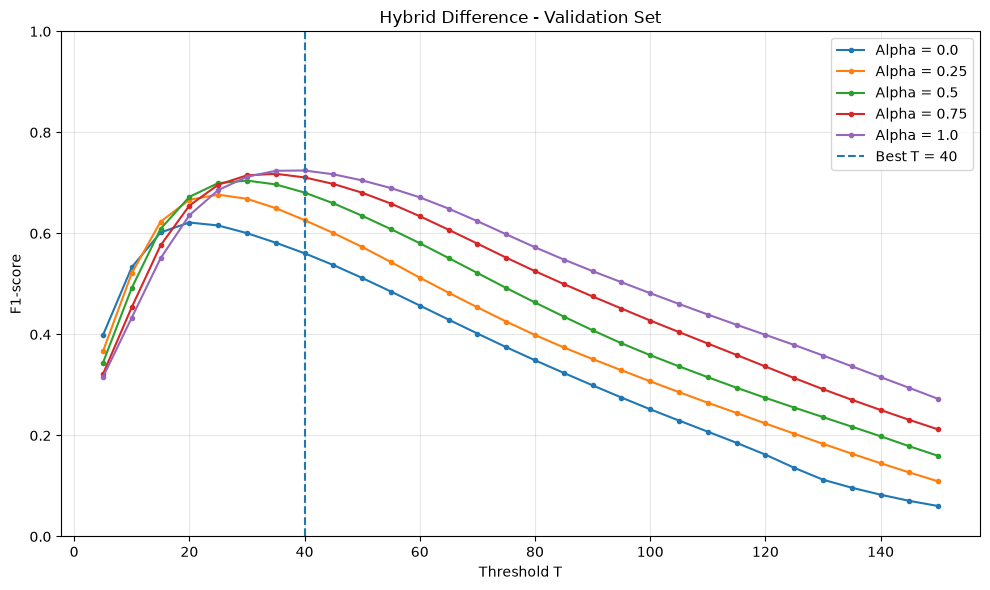

In [5]:
plt.figure(figsize=(10, 6))

for alpha in alphas:

    subset = results_df[
        results_df["Alpha"] == alpha
    ]

    plt.plot(
        subset["Threshold"],
        subset["F1"],
        marker=".",
        label=f"Alpha = {alpha}"
    )

plt.axvline(
    best_T,
    linestyle="--",
    label=f"Best T = {best_T}"
)

plt.xlabel("Threshold T")
plt.ylabel("F1-score")
plt.title("Hybrid Difference - Validation Set")
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    output_dir / "hybrid_threshold_comparison.png",
    dpi=300
)

plt.show()


In [6]:
i_best = alphas.index(best_alpha)
j_best = thresholds.index(best_T)

print(f"Per-category results: Alpha={best_alpha}, T={best_T}")
print(f"{'Category':15s} {'F1':>8s} {'IoU':>8s}")

category_rows = []

for category in categories:

    p, r, f1, iou = calculate_metrics(
        category_counts[category][i_best, j_best]
    )

    print(
        f"{category:15s} "
        f"{f1:8.4f} "
        f"{iou:8.4f}"
    )

    category_rows.append({
        "Category": category,
        "Precision": p,
        "Recall": r,
        "F1": f1,
        "IoU": iou
    })

pd.DataFrame(category_rows).to_csv(
    output_dir / "hybrid_category_results.csv",
    index=False
)


Per-category results: Alpha=1.0, T=40
Category              F1      IoU
blackspot         0.5416   0.3714
colorshift        0.7641   0.6182
friction          0.4647   0.3027
hair              0.4990   0.3324
line              0.2004   0.1114
pinhole           0.5805   0.4089
